# El Juego de los Números Uniformes
**Taller de Resolución de Problemas III — Universidad Austral — 2026**

Integrantes: (completar)

## Método de resolución

Resolvemos el problema de forma **analítica** y verificamos cada resultado con **simulación (Monte Carlo)**.

Lo hacemos en dos etapas:

1. **Etapa 1:** el Jugador 1 frente a un rival con un número uniforme (0,1), eligiendo para cada número la opción con mayor probabilidad de ganar.
2. **Etapa 2:** el juego completo, donde el Jugador 2 conoce la opción elegida por el Jugador 1 (pero no su número) y decide en consecuencia.

## Etapa 1: rival uniforme (0,1)

### Hipótesis

1. El número final del rival es **uniforme en (0,1)**: el rival no elige ninguna opción, tiene un número al azar.
2. El Jugador 1 elige, para cada número que le toca, la opción con **mayor probabilidad de ganar**.
3. Los números son independientes entre sí.
4. La probabilidad de empate es 0 (dos números uniformes casi nunca son iguales).

### Resolución

Nos toca un número $x$ y comparamos la probabilidad de ganar de cada opción:

- **Plantarse:** termino con $x$. Gano si el rival tiene menos que $x$ → $P = x$
- **Complementar:** termino con $1-x$. Gano si el rival tiene menos que $1-x$ → $P = 1-x$
- **Sortear de nuevo:** los dos tenemos un número al azar con la misma distribución; por simetría cada uno gana la mitad de las veces → $P = 0.5$

**Ejemplos:**

- $x = 0.9$: plantarse 0.9, complementar 0.1, sortear 0.5 → **me planto**
- $x = 0.2$: plantarse 0.2, complementar 0.8, sortear 0.5 → **complemento**
- $x = 0.45$: plantarse 0.45, complementar 0.55, sortear 0.5 → **complemento** (por poco)

Entre $x$ y $1-x$, siempre uno de los dos es al menos 0.5. Entonces **sortear nunca conviene**.

**Estrategia:** me planto si $x \geq 0.5$ y complemento si $x < 0.5$. Siempre termino con $\max(x, 1-x)$.

In [1]:
import numpy as np

def mejor_opcion(x):
    p_plantarse = x
    p_complementar = 1 - x
    p_sortear = 0.5

    if p_plantarse >= p_complementar and p_plantarse >= p_sortear:
        return "plantarse", p_plantarse
    elif p_complementar >= p_sortear:
        return "complementar", p_complementar
    else:
        return "sortear", p_sortear

In [2]:
for x in [0.9, 0.2, 0.45, 0.5, 0.6]:
    opcion, prob = mejor_opcion(x)
    print("x =", x, "→", opcion, "con P(ganar) =", round(prob, 2))

x = 0.9 → plantarse con P(ganar) = 0.9
x = 0.2 → complementar con P(ganar) = 0.8
x = 0.45 → complementar con P(ganar) = 0.55
x = 0.5 → plantarse con P(ganar) = 0.5
x = 0.6 → plantarse con P(ganar) = 0.6


In [6]:

from scipy.integrate import quad

# Probabilidad media cuando conviene complementar
parte1, _ = quad(lambda x: 1 - x, 0, 0.5)

# Probabilidad media cuando conviene plantarse
parte2, _ = quad(lambda x: x, 0.5, 1)

probabilidad_total = parte1 + parte2

print("Probabilidad teórica:", probabilidad_total)
print("Probabilidad en porcentaje:", probabilidad_total * 100, "%")


Probabilidad teórica: 0.75
Probabilidad en porcentaje: 75.0 %


### Verificación por simulación

Para un número fijo $x$, jugamos muchas veces contra un rival uniforme (0,1) y contamos cuántas veces gana cada opción. Si las cuentas están bien, tiene que dar cerca de $x$, $1-x$ y $0.5$.

In [3]:
def simular_opciones(x, n):
    rival = np.random.rand(n)            # números del rival, uniformes (0,1)
    nuevo = np.random.rand(n)            # número nuevo si sorteo

    gana_plantarse = np.mean(x > rival)
    gana_complementar = np.mean(1 - x > rival)
    gana_sortear = np.mean(nuevo > rival)

    return gana_plantarse, gana_complementar, gana_sortear

for x in [0.9, 0.2, 0.45]:
    p1, p2, p3 = simular_opciones(x, 100000)
    print("x =", x, "| plantarse:", round(p1, 3), "| complementar:", round(p2, 3), "| sortear:", round(p3, 3))

x = 0.9 | plantarse: 0.9 | complementar: 0.1 | sortear: 0.5
x = 0.2 | plantarse: 0.199 | complementar: 0.801 | sortear: 0.5
x = 0.45 | plantarse: 0.45 | complementar: 0.55 | sortear: 0.5


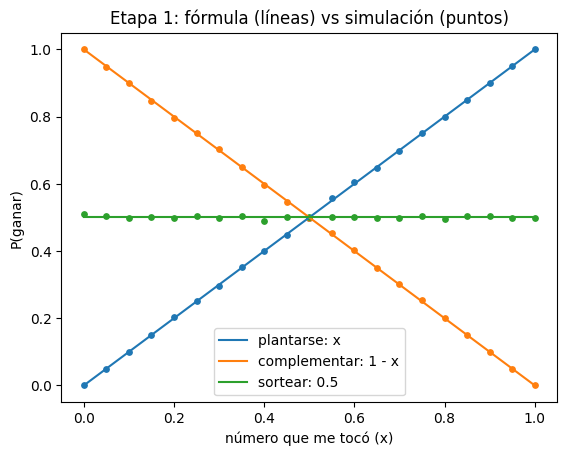

In [4]:
import matplotlib.pyplot as plt

xs = np.linspace(0, 1, 21)    # 0, 0.05, 0.10, ..., 1

sim_plantarse = []
sim_complementar = []
sim_sortear = []

for x in xs:
    p1, p2, p3 = simular_opciones(x, 20000)
    sim_plantarse.append(p1)
    sim_complementar.append(p2)
    sim_sortear.append(p3)

# fórmulas (líneas) vs simulación (puntos)
plt.plot(xs, xs, label="plantarse: x")
plt.plot(xs, 1 - xs, label="complementar: 1 - x")
plt.plot(xs, [0.5] * len(xs), label="sortear: 0.5")

plt.scatter(xs, sim_plantarse, s=15)
plt.scatter(xs, sim_complementar, s=15)
plt.scatter(xs, sim_sortear, s=15)

plt.xlabel("número que me tocó (x)")
plt.ylabel("P(ganar)")
plt.title("Etapa 1: fórmula (líneas) vs simulación (puntos)")
plt.legend()
plt.show()

### Probabilidad total de ganar con esta estrategia

Siempre termino con $\max(x, 1-x)$, que es un número entre 0.5 y 1, y gano con esa misma probabilidad. En promedio:

$$P(\text{ganar}) = E[\max(x, 1-x)] = 0.75$$

Lo comprobamos simulando partidas completas:

In [5]:
def jugar_etapa1(n):
    x = np.random.rand(n)
    mi_numero = np.maximum(x, 1 - x)     # me planto o complemento, el mayor
    rival = np.random.rand(n)
    return np.mean(mi_numero > rival)

print("P(ganar) simulada:", round(jugar_etapa1(1000000), 4))

P(ganar) simulada: 0.7496


### ¿Qué falla de esta etapa?

El resultado dice que ganamos el 75% de las veces, pero **el rival también puede elegir**. Si el Jugador 2 usa la misma estrategia, cada uno gana el 50%. Entonces el supuesto "rival uniforme (0,1)" no es realista: el rival también se queda con su mayor número, que está entre 0.5 y 1.

En la etapa 2 incorporamos la decisión del Jugador 2, que además conoce la opción que eligió el Jugador 1.